### Clustering Customers with K-Mean


#### Import LIbraries

In [18]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans 
from sklearn.metrics import silhouette_score

from google.colab import drive

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"


In [19]:
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Step 0: explore data

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Mall_Customers.csv") #actually dropp this csv into googledrive fr
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [27]:
df.shape
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [28]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### Step 1: 

In [24]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values
X

scaler = StandardScaler()   #uses mean and standard deviation;
Xs = scaler.fit_transform(X) #  ( z-score = datapoint - mean )/std 
print ("scaled values:", np.round(Xs.mean(axis=0), 3), np.round(Xs.std(axis=0), 3)) #returns mean and std 


scaled values: [-0. -0.] [1. 1.]


In [25]:
Xs #if greater than 1, its greater than the mean

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

#### Step 3: How many clusters?

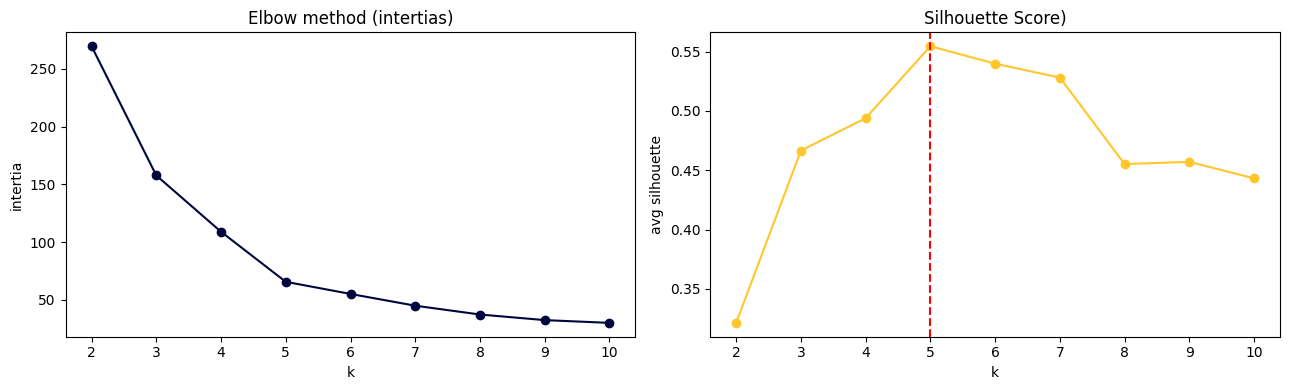

In [29]:

ks = range(2, 11)
intertias, sils = [], []

for k in ks:
  km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
  intertias.append(km.inertia_)
  sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize =(13, 4))
ax[0].plot(list(ks), intertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (intertias)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("intertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette Score)"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")

# retrieving the best k (prints as red line)
best_k = list(ks)[int(np.argmax(sils))] # same as writing [2, 3, 4, 5][2] basically indexing the list

ax[1].axvline(best_k, color="red", linestyle="--")
plt.tight_layout(); plt.show()